# Lab 7 – Định lý giới hạn trung tâm

## Nội Dung Bài Học

1. Định lý giới hạn trung tâm.
2. Lấy mẫu từ phân phối đều.
3. Lấy mẫu từ phân phối mũ.
4. Lấy mẫu từ phân phối nhị thức.
5. Bài tập thực hành về phân phối trung bình mẫu, sai số chuẩn và xác suất.

## Phần I. Lý Thuyết

### 1. Định lý giới hạn trung tâm

Định lý giới hạn trung tâm (Central Limit Theorem, CLT) cho biết: khi cỡ mẫu đủ lớn, phân phối của trung bình mẫu tiến gần đến phân phối chuẩn, ngay cả khi phân phối tổng thể không chuẩn. Xét các quan sát độc lập, cùng phân phối, với kỳ vọng $\mu$ và phương sai hữu hạn $\sigma^2$:

$$\overline{X}=\frac{1}{n}\sum_{i=1}^{n}X_i,\qquad E[\overline{X}]=\mu,\qquad SE=\frac{\sigma}{\sqrt{n}}.$$

Với $n$ đủ lớn:

$$\overline{X}\approx\mathcal{N}\!\left(\mu,\frac{\sigma^2}{n}\right),$$

trong đó tham số thứ hai là **phương sai**, còn độ lệch chuẩn là $\sigma/\sqrt{n}$.

**Các điểm chính:**

- **Dạng phân phối:** phân phối trung bình mẫu tiến gần đường cong chuẩn hình chuông khi cỡ mẫu tăng, kể cả với tổng thể lệch, đều hoặc nhị thức.
- **Trung bình:** kỳ vọng của trung bình mẫu bằng trung bình tổng thể $\mu$.
- **Sai số chuẩn:** $SE=\sigma/\sqrt{n}$ giảm khi $n$ tăng; các trung bình mẫu tập trung hơn quanh $\mu$.
- **Sự hội tụ:** $n\geq30$ thường được dùng như quy tắc kinh nghiệm, nhưng mức độ xấp xỉ còn phụ thuộc phân phối tổng thể, đặc biệt khi tổng thể rất lệch.
- **Ứng dụng:** CLT hỗ trợ suy luận về trung bình tổng thể, kiểm định giả thuyết, khoảng tin cậy và tính xác suất bằng xấp xỉ chuẩn.

Trong các ví dụ sau, mỗi lần mô phỏng tạo 1.000 mẫu độc lập, mỗi mẫu có 30 quan sát. Histogram biểu diễn mật độ của 1.000 trung bình mẫu; đường màu đỏ là mật độ chuẩn với trung bình và độ lệch chuẩn ước lượng từ các trung bình mẫu.

### 2. Lấy mẫu từ phân phối đều

Phân phối đều trên khoảng $[0,1]$ có dạng phẳng. Phân phối của trung bình mẫu có xu hướng gần chuẩn.

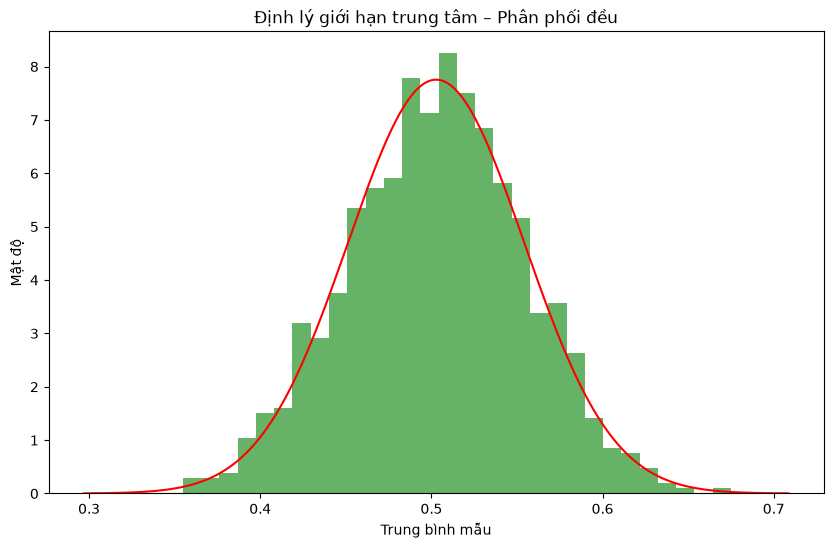

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
n = 30  # Số quan sát trong mỗi mẫu
num_samples = 1000  # Số mẫu độc lập
uniform_samples = rng.uniform(low=0, high=1, size=(num_samples, n))
sample_means = np.mean(uniform_samples, axis=1)

mean = np.mean(sample_means)
std = np.std(sample_means)
x = np.linspace(mean - 4 * std, mean + 4 * std, 1000)
normal_density = np.exp(-(x - mean)**2 / (2 * std**2)) / (std * np.sqrt(2 * np.pi))

plt.figure(figsize=(10, 6))
plt.hist(sample_means, bins=30, density=True, alpha=0.6, color='g')
plt.plot(x, normal_density, color='r')
plt.title('Định lý giới hạn trung tâm – Phân phối đều')
plt.xlabel('Trung bình mẫu')
plt.ylabel('Mật độ')
plt.show()


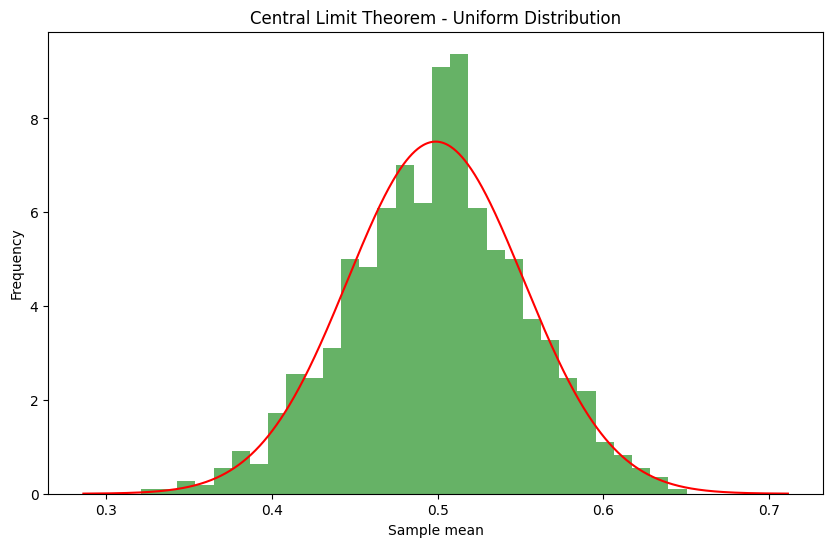

### 3. Lấy mẫu từ phân phối mũ

Phân phối mũ với tham số tỷ lệ `scale=1` lệch phải rõ rệt. Khi cỡ mẫu tăng, phân phối trung bình mẫu vẫn tiến gần phân phối chuẩn.

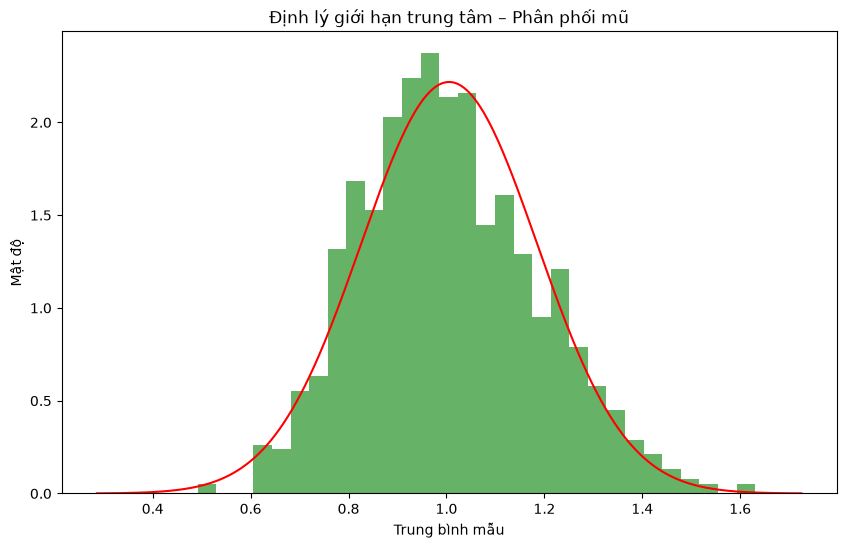

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
n = 30  # Số quan sát trong mỗi mẫu
num_samples = 1000  # Số mẫu độc lập
exponential_samples = rng.exponential(scale=1, size=(num_samples, n))
sample_means = np.mean(exponential_samples, axis=1)

mean = np.mean(sample_means)
std = np.std(sample_means)
x = np.linspace(mean - 4 * std, mean + 4 * std, 1000)
normal_density = np.exp(-(x - mean)**2 / (2 * std**2)) / (std * np.sqrt(2 * np.pi))

plt.figure(figsize=(10, 6))
plt.hist(sample_means, bins=30, density=True, alpha=0.6, color='g')
plt.plot(x, normal_density, color='r')
plt.title('Định lý giới hạn trung tâm – Phân phối mũ')
plt.xlabel('Trung bình mẫu')
plt.ylabel('Mật độ')
plt.show()


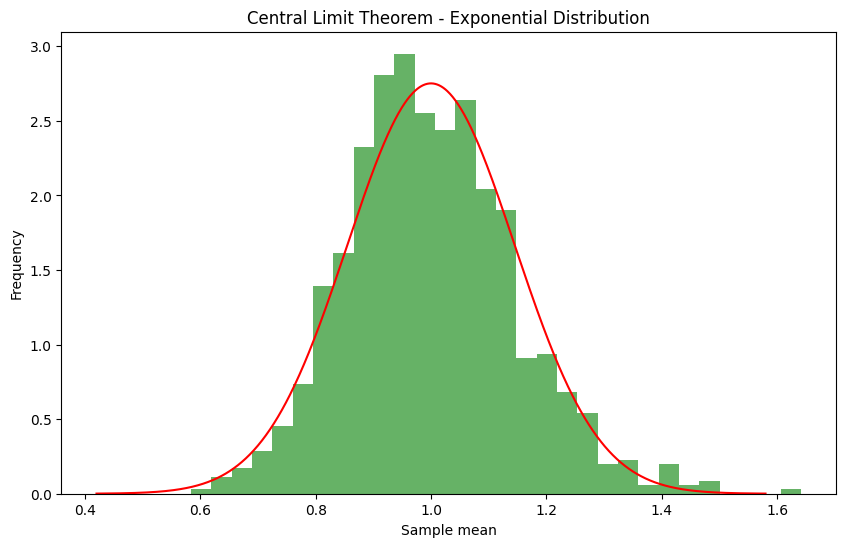

### 4. Lấy mẫu từ phân phối nhị thức

Lấy mẫu từ phân phối nhị thức với 10 phép thử và xác suất thành công 0,5. Ví dụ này cho thấy CLT cũng áp dụng cho biến ngẫu nhiên rời rạc.

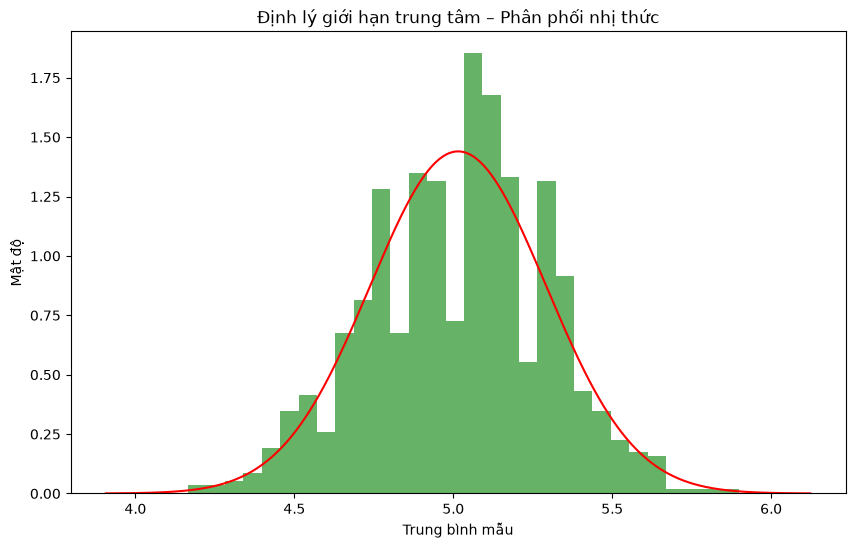

In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
n = 30  # Số quan sát trong mỗi mẫu
num_samples = 1000  # Số mẫu độc lập
binomial_samples = rng.binomial(n=10, p=0.5, size=(num_samples, n))
sample_means = np.mean(binomial_samples, axis=1)

mean = np.mean(sample_means)
std = np.std(sample_means)
x = np.linspace(mean - 4 * std, mean + 4 * std, 1000)
normal_density = np.exp(-(x - mean)**2 / (2 * std**2)) / (std * np.sqrt(2 * np.pi))

plt.figure(figsize=(10, 6))
plt.hist(sample_means, bins=30, density=True, alpha=0.6, color='g')
plt.plot(x, normal_density, color='r')
plt.title('Định lý giới hạn trung tâm – Phân phối nhị thức')
plt.xlabel('Trung bình mẫu')
plt.ylabel('Mật độ')
plt.show()


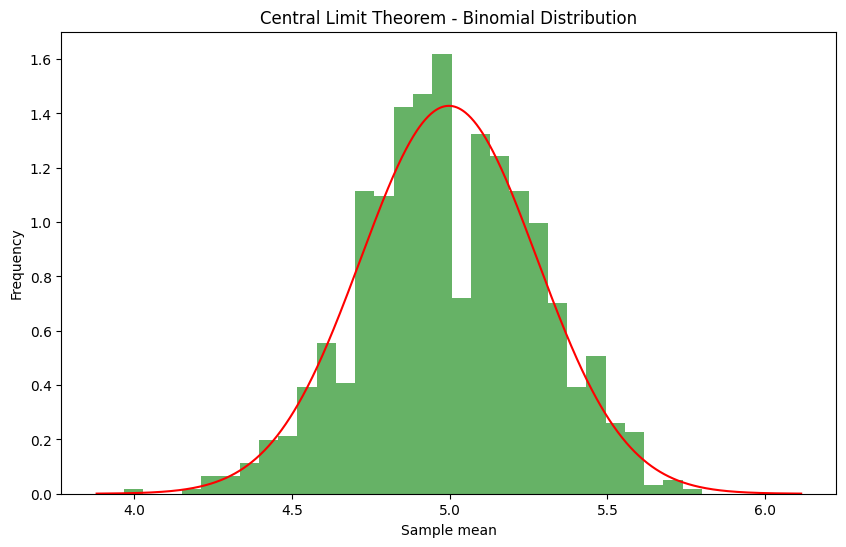

## Phần II. Bài tập thực hành

### Bài tập 1. Hiểu về CLT

Xét một tổng thể có phân phối rất lệch, chẳng hạn phân phối mũ với trung bình bằng 5. Lấy các mẫu ngẫu nhiên có cỡ mẫu 30 từ tổng thể này. Theo định lý giới hạn trung tâm:

a) Phân phối của các trung bình mẫu có dạng gì?

b) Khi cỡ mẫu tăng, phân phối của các trung bình mẫu thay đổi như thế nào?

In [9]:
def solve_exercise_1():
    print("a. Phân phối của các trung bình mẫu sẽ có dạng xấp xỉ phân phối chuẩn")
    print(
        "b. Khi cỡ mẫu tăng, phân phối của các trung bình mẫu sẽ ngày càng hội tụ sát về phân phối chuẩn"
    )

solve_exercise_1()

a. Phân phối của các trung bình mẫu sẽ có dạng xấp xỉ phân phối chuẩn
b. Khi cỡ mẫu tăng, phân phối của các trung bình mẫu sẽ ngày càng hội tụ sát về phân phối chuẩn


### Bài tập 2. Phân phối trung bình mẫu

Chiều cao của một tổng thể có phân phối lệch, trung bình 170 cm và độ lệch chuẩn 15 cm. Mỗi lần lấy ngẫu nhiên 40 người.

a) Kỳ vọng của phân phối trung bình mẫu bằng bao nhiêu?

b) Độ lệch chuẩn của phân phối trung bình mẫu (sai số chuẩn) bằng bao nhiêu?

In [5]:
import numpy as np

def solve_exercise_2():
    mu = 170
    sigma = 15
    n = 40
    ky_vong = mu
    se = sigma / np.sqrt(n)
    print("a. Ky vong:", ky_vong)
    print("b. Sai so chuan:", round(se, 4))

solve_exercise_2()

a. Ky vong: 170
b. Sai so chuan: 2.3717


### Bài tập 3. Tính xác suất bằng CLT

Cân nặng của một tổng thể có phân phối chuẩn với trung bình 70 kg và độ lệch chuẩn 10 kg. Lấy một mẫu ngẫu nhiên gồm 50 người. Tính xác suất trung bình cân nặng của mẫu nằm trong khoảng từ 68 kg đến 72 kg.

In [6]:
import numpy as np
import scipy.stats as stats

def solve_exercise_3():
    mu = 70
    sigma = 10
    n = 50
    se = sigma / np.sqrt(n)
    p = stats.norm.cdf(72, loc=mu, scale=se) - stats.norm.cdf(68, loc=mu, scale=se)
    print("Xac suat:", round(p, 4))

solve_exercise_3()

Xac suat: 0.8427


### Bài tập 4. Xấp xỉ phân phối nhị thức bằng CLT

Một nhà máy sản xuất bóng đèn; xác suất một bóng bị lỗi là 0,05. Lấy ngẫu nhiên 200 bóng. Sử dụng định lý giới hạn trung tâm để xấp xỉ xác suất có **hơn 12 bóng** bị lỗi trong mẫu.

In [7]:
import numpy as np
import scipy.stats as stats

def solve_exercise_4():
    n = 200
    p = 0.05
    mu = n * p
    sigma = np.sqrt(n * p * (1 - p))
    p_cc = 1 - stats.norm.cdf((12.5 - mu) / sigma)
    p_raw = 1 - stats.norm.cdf((12 - mu) / sigma)
    print("Xac suat co hieu chinh lien tuc:", round(p_cc, 4))
    print("Xac suat khong hieu chinh lien tuc:", round(p_raw, 4))

solve_exercise_4()

Xac suat co hieu chinh lien tuc: 0.2087
Xac suat khong hieu chinh lien tuc: 0.2582


### Bài tập 5. Ảnh hưởng của cỡ mẫu

Một tổng thể có trung bình 100 và độ lệch chuẩn 20. Lấy các mẫu có cỡ mẫu 25 và tính trung bình mẫu.

a) Kỳ vọng và sai số chuẩn của các trung bình mẫu bằng bao nhiêu?

b) Nếu tăng cỡ mẫu lên 100, sai số chuẩn thay đổi như thế nào?

In [8]:
import numpy as np

def solve_exercise_5():
    mu = 100
    sigma = 20
    se1 = sigma / np.sqrt(25)
    se2 = sigma / np.sqrt(100)
    print("a. Ky vong:", mu)
    print("   Sai so chuan:", round(se1, 4))
    print("b. Sai so chuan moi:", round(se2, 4))
    print("   Sai so chuan giam 2 lan")

solve_exercise_5()

a. Ky vong: 100
   Sai so chuan: 4.0
b. Sai so chuan moi: 2.0
   Sai so chuan giam 2 lan
